In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import zscore
from matplotlib.colors import Colormap
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
plt.style.use('ggplot')
from matplotlib.pyplot import figure
%matplotlib inline
matplotlib.rcParams["figure.figsize"] = (12, 8)

In [4]:
import warnings
warnings.filterwarnings("ignore" ,category=FutureWarning)

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
file_path = "/content/drive/MyDrive/Final Data Mining-Kelompok 2/Neural Network/Dataset/train.csv"

data = pd.read_csv(file_path)
data.head()

Mounted at /content/drive


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [6]:
Useless_Columns = [data.columns[0], 'id' , 'Gender', 'Ease of Online booking','Food and drink','Departure/Arrival time convenient']

for col in Useless_Columns:
    data = data.drop(col, axis=1)

Informasi Data

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 19 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Customer Type               103904 non-null  object 
 1   Age                         103904 non-null  int64  
 2   Type of Travel              103904 non-null  object 
 3   Class                       103904 non-null  object 
 4   Flight Distance             103904 non-null  int64  
 5   Inflight wifi service       103904 non-null  int64  
 6   Gate location               103904 non-null  int64  
 7   Online boarding             103904 non-null  int64  
 8   Seat comfort                103904 non-null  int64  
 9   Inflight entertainment      103904 non-null  int64  
 10  On-board service            103904 non-null  int64  
 11  Leg room service            103904 non-null  int64  
 12  Baggage handling            103904 non-null  int64  
 13  Checkin servic

In [8]:
data.isnull().sum()

,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Gate location,0
Online boarding,0
Seat comfort,0
Inflight entertainment,0


count    103594.000000
mean         15.178678
std          38.698682
min           0.000000
25%           0.000000
50%           0.000000
75%          13.000000
max        1584.000000
Name: Arrival Delay in Minutes, dtype: float64


<Axes: xlabel='Arrival Delay in Minutes'>

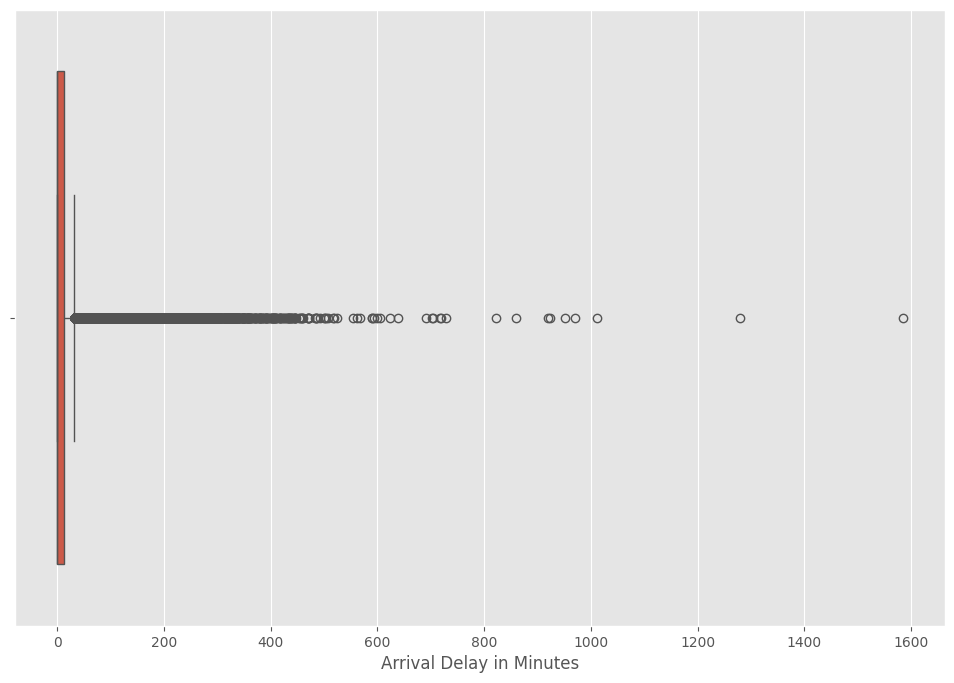

In [9]:
# Melihat ringkasan data
print(data['Arrival Delay in Minutes'].describe())

# Cek distribusi
import seaborn as sns
sns.boxplot(x=data['Arrival Delay in Minutes'])  # Untuk melihat outlier


In [10]:
median_delay = data['Arrival Delay in Minutes'].median()

In [11]:
data['Arrival Delay in Minutes'].fillna(median_delay, inplace=True)

In [12]:
data.isnull().sum()

,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Gate location,0
Online boarding,0
Seat comfort,0
Inflight entertainment,0


In [13]:
label_encoder = LabelEncoder()
data['Customer Type'] = label_encoder.fit_transform(data['Customer Type'])
data['Type of Travel'] = label_encoder.fit_transform(data['Type of Travel'])
data['Class'] = label_encoder.fit_transform(data['Class'])

In [14]:
data['satisfaction'] = data['satisfaction'].map({'neutral or dissatisfied': 0, 'satisfied': 1})

In [15]:
data.head(10)

,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Gate location,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,13,1,2,460,3,1,3,5,5,4,3,4,4,5,5,25,18.0,0
1,1,25,0,0,235,3,3,3,1,1,1,5,3,1,4,1,1,6.0,0
2,0,26,0,0,1142,2,2,5,5,5,4,3,4,4,4,5,0,0.0,1
3,0,25,0,0,562,2,5,2,2,2,2,5,3,1,4,2,11,9.0,0
4,0,61,0,0,214,3,3,5,5,3,3,4,4,3,3,3,0,0.0,1
5,0,26,1,1,1180,3,1,2,1,1,3,4,4,4,4,1,0,0.0,0
6,0,47,1,1,1276,2,3,2,2,2,3,3,4,3,5,2,9,23.0,0
7,0,52,0,0,2035,4,4,5,5,5,5,5,5,4,5,4,4,0.0,1
8,0,41,0,0,853,1,2,3,3,1,1,2,1,4,1,2,0,0.0,0
9,1,20,0,1,1061,3,4,3,3,2,2,3,4,4,3,2,0,0.0,0


Visualisasi Data

satisfaction
0    58879
1    45025
Name: count, dtype: int64


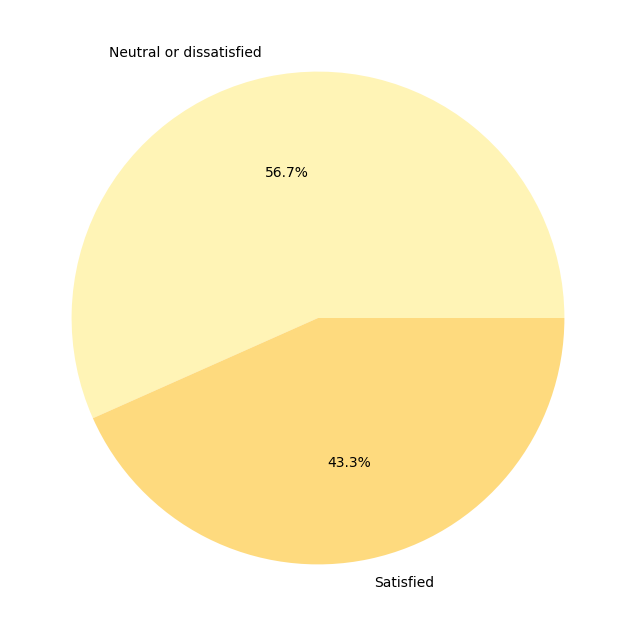

In [16]:
plt.pie(data.satisfaction.value_counts(), labels = ["Neutral or dissatisfied", "Satisfied"], colors = sns.color_palette("YlOrBr"), autopct = '%1.1f%%')
pass

print(data['satisfaction'].value_counts())

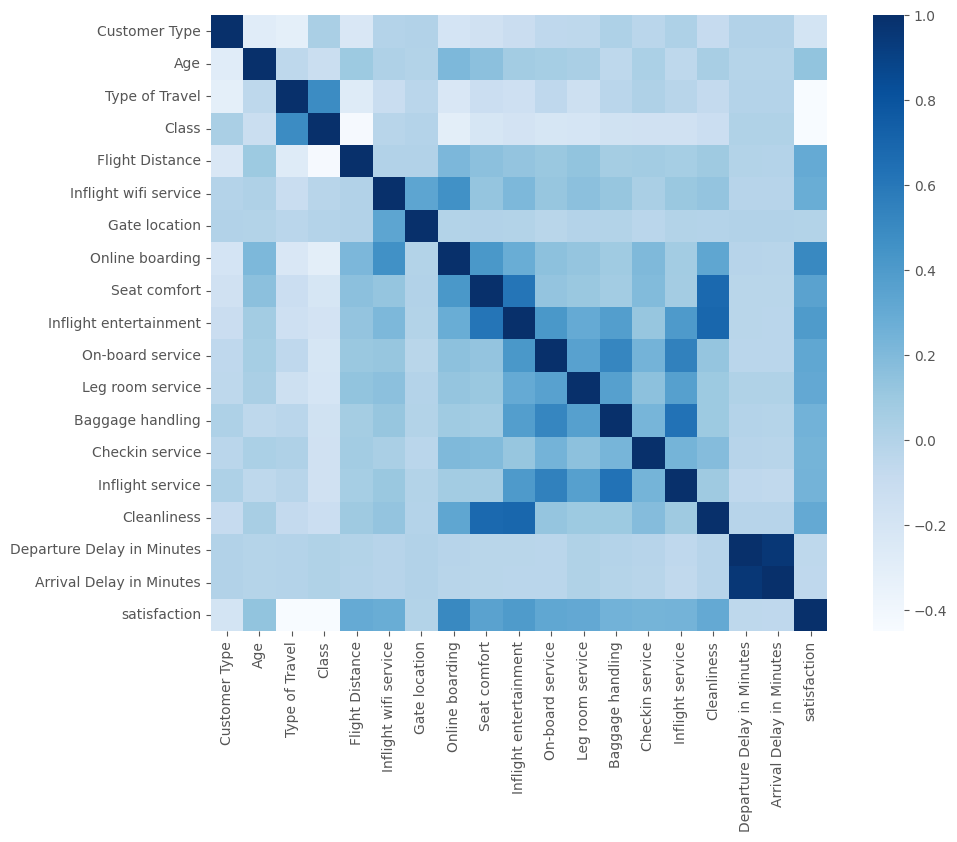

In [17]:
corr_mat = data.corr()
sns.heatmap(corr_mat, square = True, cmap = 'Blues')
pass

Data Preprocessing

In [18]:
z_scores = np.abs(zscore(data))

In [19]:
threshold = 3
# removing outliers using z-score method
no_outliers = data[(np.abs(data - data.mean() / data.std()) <= threshold).any(axis = 1)]
data = no_outliers
data.head(5)

,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Gate location,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,13,1,2,460,3,1,3,5,5,4,3,4,4,5,5,25,18.0,0
1,1,25,0,0,235,3,3,3,1,1,1,5,3,1,4,1,1,6.0,0
2,0,26,0,0,1142,2,2,5,5,5,4,3,4,4,4,5,0,0.0,1
3,0,25,0,0,562,2,5,2,2,2,2,5,3,1,4,2,11,9.0,0
4,0,61,0,0,214,3,3,5,5,3,3,4,4,3,3,3,0,0.0,1


Data Trandformation

In [20]:
scaler = MinMaxScaler()
data = pd.DataFrame(scaler.fit_transform(data) , columns = data.columns)

In [21]:
data.head(5)

,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Gate location,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0.0,0.076923,1.0,1.0,0.086632,0.6,0.2,0.6,1.0,1.0,0.8,0.6,0.75,0.8,1.0,1.0,0.015704,0.011364,0.0
1,1.0,0.230769,0.0,0.0,0.041195,0.6,0.6,0.6,0.2,0.2,0.2,1.0,0.50,0.2,0.8,0.2,0.000628,0.003788,0.0
2,0.0,0.243590,0.0,0.0,0.224354,0.4,0.4,1.0,1.0,1.0,0.8,0.6,0.75,0.8,0.8,1.0,0.000000,0.000000,1.0
3,0.0,0.230769,0.0,0.0,0.107229,0.4,1.0,0.4,0.4,0.4,0.4,1.0,0.50,0.2,0.8,0.4,0.006910,0.005682,0.0
4,0.0,0.692308,0.0,0.0,0.036955,0.6,0.6,1.0,1.0,0.6,0.6,0.8,0.75,0.6,0.6,0.6,0.000000,0.000000,1.0


Korelasi

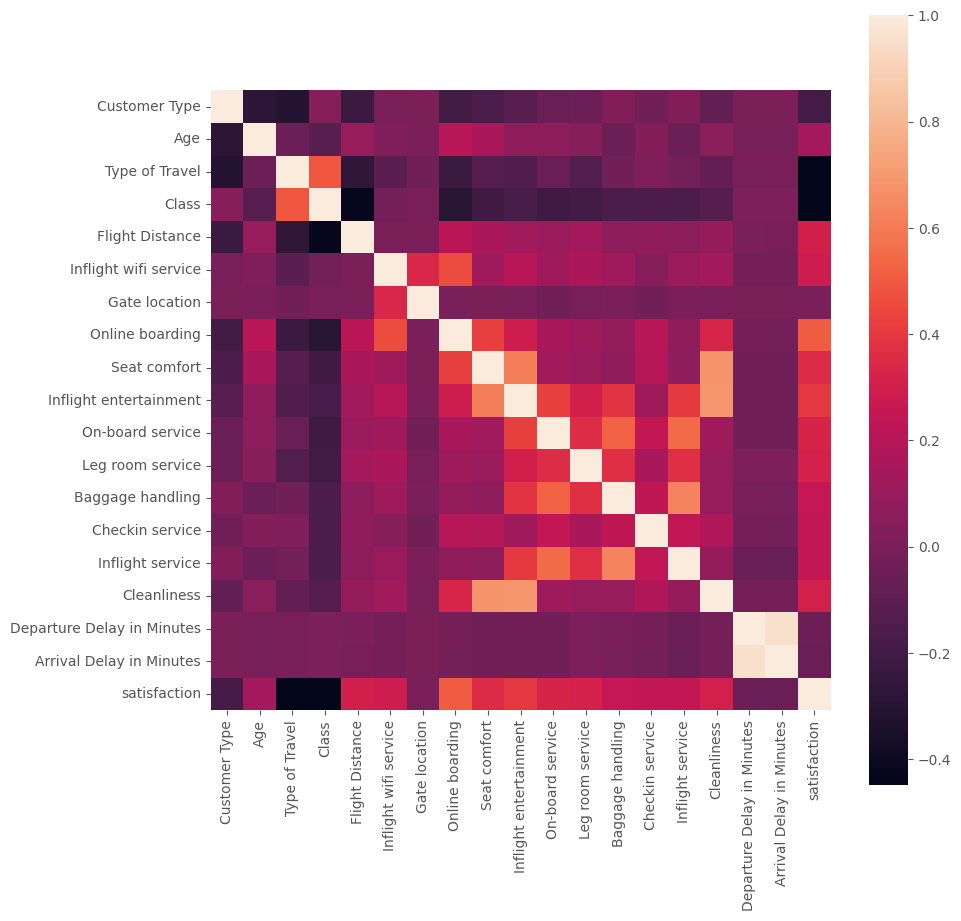

In [22]:
corrmat = data.corr()
f, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(corrmat, vmax= 1, square=True);

Split features and label

In [23]:
X = data.drop('satisfaction', axis=1)
y = data['satisfaction']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [24]:
scaler = MinMaxScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train) , columns = X.columns)
X_test = pd.DataFrame(scaler.fit_transform(X_test) , columns = X.columns)

Bangun Model

In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input , Dropout
from tensorflow.keras.layers import Dense


model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(16, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='relu'))

In [26]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [27]:
history = model.fit(X_train, y_train, epochs=100, batch_size=10, validation_data=(X_test, y_test))

Epoch 1/100
7793/7793 ━━━━━━━━━━━━━━━━━━━━ 36s 4ms/step - accuracy: 0.7309 - loss: 0.7196 - val_accuracy: 0.5865 - val_loss: 0.6491
Epoch 2/100
7793/7793 ━━━━━━━━━━━━━━━━━━━━ 35s 4ms/step - accuracy: 0.7906 - loss: 0.5480 - val_accuracy: 0.8949 - val_loss: 0.3078
Epoch 3/100
7793/7793 ━━━━━━━━━━━━━━━━━━━━ 41s 4ms/step - accuracy: 0.8691 - loss: 0.4219 - val_accuracy: 0.8970 - val_loss: 0.2447
Epoch 4/100
7793/7793 ━━━━━━━━━━━━━━━━━━━━ 39s 4ms/step - accuracy: 0.8826 - loss: 0.3597 - val_accuracy: 0.8863 - val_loss: 0.2520
Epoch 5/100
7793/7793 ━━━━━━━━━━━━━━━━━━━━ 33s 4ms/step - accuracy: 0.8943 - loss: 0.3364 - val_accuracy: 0.8483 - val_loss: 0.3244
Epoch 6/100
7793/7793 ━━━━━━━━━━━━━━━━━━━━ 43s 5ms/step - accuracy: 0.8940 - loss: 0.3526 - val_accuracy: 0.9027 - val_loss: 0.2148
Epoch 7/100
7793/7793 ━━━━━━━━━━━━━━━━━━━━ 45s 5ms/step - accuracy: 0.9041 - loss: 0.3158 - val_accuracy: 0.8970 - val_loss: 0.2246
Epoch 8/100
7793/7793 ━━━━━━━━━━━━━━━━━━━━ 35s 4ms/step - accuracy: 0.8944 -

In [28]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Loss: {loss}, Accuracy: {accuracy}')

812/812 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9424 - loss: 0.1555
Loss: 0.15886278450489044, Accuracy: 0.9410609602928162
